In [ ]:
# %pip installs into the kernel's own Python environment (plain pip may not)
%pip install kagglehub pandas numpy scikit-learn xgboost matplotlib seaborn

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("marwa80/userbehavior")

print("Path to dataset files:", path)


Path to dataset files: /Users/madhumithachandrasekaran/.cache/kagglehub/datasets/marwa80/userbehavior/versions/1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')

In [2]:
col_names = ['user_id', 'item_id', 'category_id', 'behavior_type', 'timestamp']

df_full = pd.read_csv(
    '/Users/madhumithachandrasekaran/.cache/kagglehub/datasets/marwa80/userbehavior/versions/1/UserBehavior.csv',
    names=col_names,
    dtype={'user_id': 'int32', 'item_id': 'int32', 'category_id': 'int32',
           'behavior_type': 'category', 'timestamp': 'int32'}
)

print(f"Full dataset: {len(df_full):,} rows, {df_full['user_id'].nunique():,} unique users")

Full dataset: 100,150,807 rows, 987,994 unique users


In [3]:
np.random.seed(42)
sample_users = np.random.choice(df_full['user_id'].unique(), size=10_000, replace=False)
df = df_full[df_full['user_id'].isin(sample_users)].copy()
del df_full  #free memory

# Convert timestamp to datetime in Beijing time (UTC+8), the platform's local time
# Without the +8h shift, hours are in UTC and the date window below is off by 8 hours
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s') + pd.Timedelta(hours=8)

# Keep only the documented collection window (a few rows have bad timestamps)
before_rows = len(df)
df = df[(df['datetime'] >= '2017-11-25') & (df['datetime'] < '2017-12-04')]
print(f"Rows outside 2017-11-25 to 2017-12-03 removed: {before_rows - len(df):,}")
df = df.sort_values(['user_id', 'datetime']).reset_index(drop=True)

print(f"Sampled dataset: {len(df):,} rows")
print(f"Date range: {df['datetime'].min()} → {df['datetime'].max()}")
print(f"\nBehavior counts:\n{df['behavior_type'].value_counts()}")

Rows outside 2017-11-25 to 2017-12-03 removed: 582


Sampled dataset: 1,009,227 rows
Date range: 2017-11-25 00:00:00 → 2017-12-03 23:59:57

Behavior counts:
behavior_type
pv      903980
cart     55223
fav      29420
buy      20604
Name: count, dtype: int64


In [4]:
print(df.isnull().sum())
print(f"\nTotal null values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")

user_id          0
item_id          0
category_id      0
behavior_type    0
timestamp        0
datetime         0
dtype: int64

Total null values: 0
Duplicate rows: 0


In [5]:
valid_behaviors = {'pv', 'fav', 'cart', 'buy'}
invalid = ~df['behavior_type'].isin(valid_behaviors)
print(f"Invalid behavior_type values: {invalid.sum():,}")
print(df['behavior_type'].value_counts())

Invalid behavior_type values: 0
behavior_type
pv      903980
cart     55223
fav      29420
buy      20604
Name: count, dtype: int64


In [6]:
print(f"\nDatetime range: {df['datetime'].min()} → {df['datetime'].max()}")
print(f"Any future timestamps (post-2025): {(df['datetime'].dt.year > 2025).sum():,}")
print(f"Any ancient timestamps (pre-2000): {(df['datetime'].dt.year < 2000).sum():,}")


Datetime range: 2017-11-25 00:00:00 → 2017-12-03 23:59:57
Any future timestamps (post-2025): 0
Any ancient timestamps (pre-2000): 0


In [7]:
events_per_user = df.groupby('user_id').size()
print("Events per user:")
print(events_per_user.describe(percentiles=[.25, .5, .75, .95, .99]))

# IQR method
Q1 = events_per_user.quantile(0.25)
Q3 = events_per_user.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nQ1: {Q1:.0f}, Q3: {Q3:.0f}, IQR: {IQR:.0f}")
print(f"Lower bound: {lower_bound:.0f}")
print(f"Upper bound: {upper_bound:.0f}")

outlier_users = events_per_user[
    (events_per_user < lower_bound) | (events_per_user > upper_bound)
].index
print(f"Outlier users (IQR method): {len(outlier_users):,}")


Events per user:
count   10000.0000
mean      100.9227
std        86.3938
min         2.0000
25%        39.0000
50%        75.5000
75%       136.0000
95%       277.0000
99%       400.0000
max       713.0000
dtype: float64

Q1: 39, Q3: 136, IQR: 97
Lower bound: -106
Upper bound: 282
Outlier users (IQR method): 471


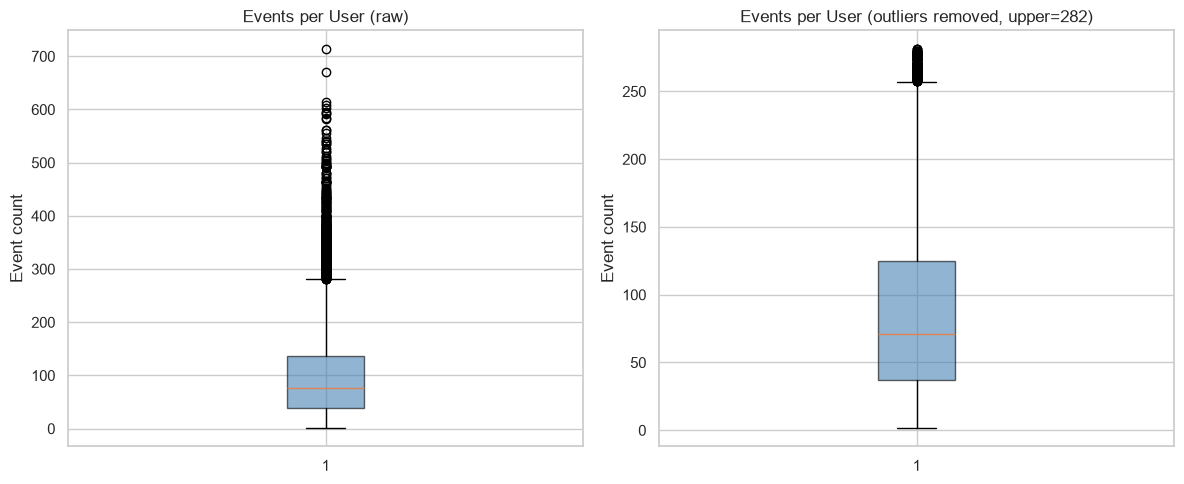

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(events_per_user, vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[0].set_title('Events per User (raw)')
axes[0].set_ylabel('Event count')

# Second plot capped at upper bound so you can see the box clearly
axes[1].boxplot(events_per_user[events_per_user <= upper_bound], vert=True,
                patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title(f'Events per User (outliers removed, upper={upper_bound:.0f})')
axes[1].set_ylabel('Event count')

plt.tight_layout()
plt.show()

In [9]:
before = df['user_id'].nunique()
df = df[~df['user_id'].isin(outlier_users)]
print(f"Users removed (IQR outliers): {before - df['user_id'].nunique():,}")
print(f"Clean dataset: {len(df):,} rows, {df['user_id'].nunique():,} users")

Users removed (IQR outliers): 471
Clean dataset: 839,613 rows, 9,529 users


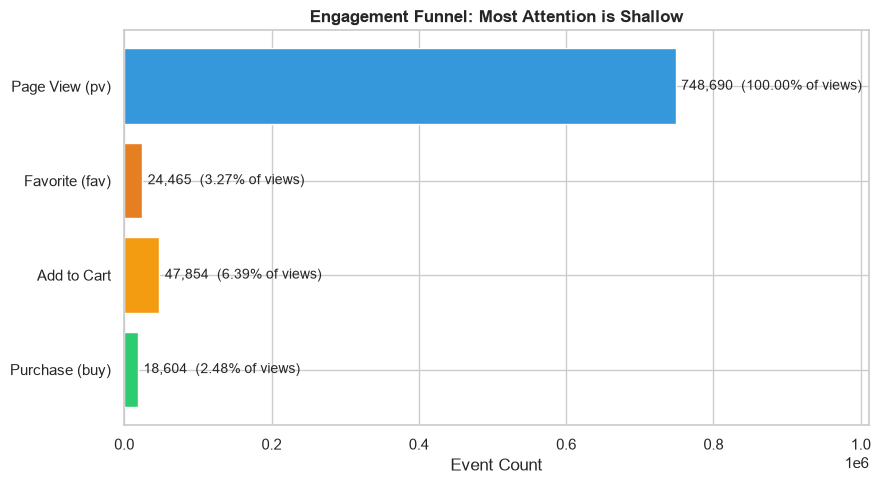

In [10]:
counts = df['behavior_type'].value_counts()
funnel = {
    'Page View (pv)':  counts.get('pv', 0),
    'Favorite (fav)':  counts.get('fav', 0),
    'Add to Cart':     counts.get('cart', 0),
    'Purchase (buy)':  counts.get('buy', 0),
}

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(list(funnel.keys())[::-1], list(funnel.values())[::-1],
               color=['#2ecc71','#f39c12','#e67e22','#3498db'])

# Add % of pv labels
pv = funnel['Page View (pv)']
for bar, (label, val) in zip(bars, reversed(list(funnel.items()))):
    pct = val / pv * 100
    ax.text(bar.get_width() + pv*0.01, bar.get_y() + bar.get_height()/2,
            f'{val:,}  ({pct:.2f}% of views)', va='center', fontsize=10)

ax.set_xlabel('Event Count')
ax.set_title('Engagement Funnel: Most Attention is Shallow', fontweight='bold')
ax.set_xlim(0, pv * 1.35)
plt.tight_layout()
plt.show()

depth_rank
Purchased        6425
Added to Cart    2019
View only         612
Favorited         473
Name: count, dtype: int64


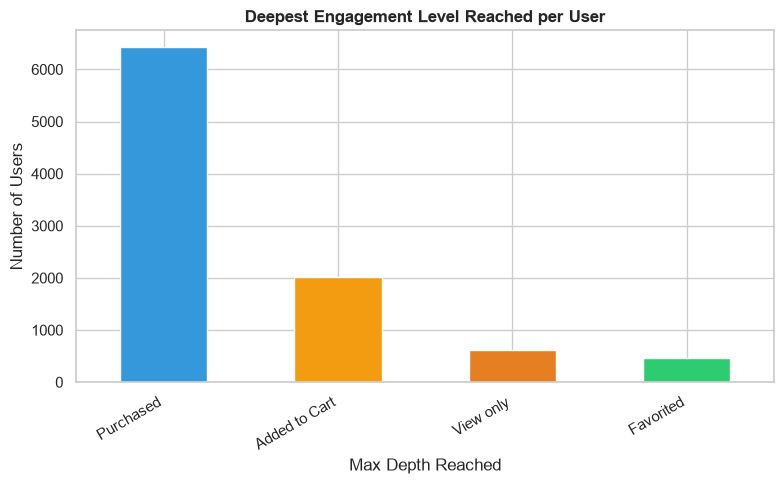

In [11]:
depth_order = {'pv': 1, 'fav': 2, 'cart': 3, 'buy': 4}
df['depth_rank'] = df['behavior_type'].map(depth_order).astype('int8')

user_max_depth = df.groupby('user_id')['depth_rank'].max()
depth_labels = {1: 'View only', 2: 'Favorited', 3: 'Added to Cart', 4: 'Purchased'}
depth_counts = user_max_depth.map(depth_labels).value_counts()

print(depth_counts)

fig, ax = plt.subplots(figsize=(8, 5))
depth_counts.plot(kind='bar', ax=ax, color=['#3498db','#f39c12','#e67e22','#2ecc71'],
                  edgecolor='white')
ax.set_title('Deepest Engagement Level Reached per User', fontweight='bold')
ax.set_xlabel('Max Depth Reached')
ax.set_ylabel('Number of Users')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [12]:
#How many unique users actually have a buy event?
buyers = df[df['behavior_type'] == 'buy']['user_id'].nunique()
total_users = df['user_id'].nunique()
print(f"Users who made at least one purchase: {buyers:,} / {total_users:,} ({buyers/total_users*100:.1f}%)")

#And how many buy events per buying user on average?
buy_events = df[df['behavior_type'] == 'buy'].groupby('user_id').size()
print(f"Avg purchases per buying user: {buy_events.mean():.2f}")
print(f"Max purchases by one user: {buy_events.max()}")

Users who made at least one purchase: 6,425 / 9,529 (67.4%)
Avg purchases per buying user: 2.90
Max purchases by one user: 34


CATEGORY CONVERSION RATES
                views  purchases  conversion_rate
category_id                                      
800581       641.0000    71.0000           0.1108
174239       550.0000    52.0000           0.0945
4159072     1729.0000   163.0000           0.0943
866301       972.0000    86.0000           0.0885
3231625      612.0000    53.0000           0.0866
2495340      625.0000    51.0000           0.0816
3747017      616.0000    49.0000           0.0795
1595193      503.0000    40.0000           0.0795
267209       517.0000    38.0000           0.0735
4919077      582.0000    42.0000           0.0722
366112       501.0000    36.0000           0.0719
50601        766.0000    53.0000           0.0692
1973012      683.0000    47.0000           0.0688
2297500      511.0000    34.0000           0.0665
846990      1109.0000    70.0000           0.0631


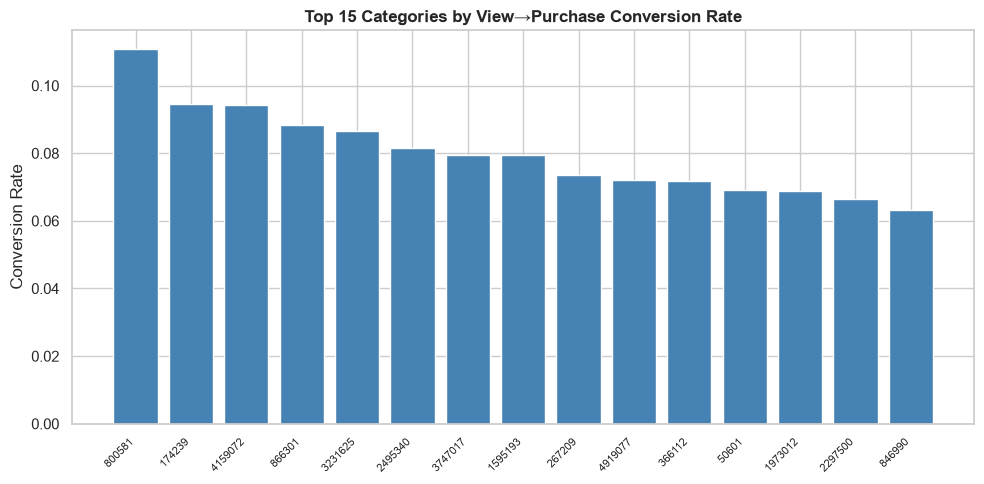

In [13]:
print("CATEGORY CONVERSION RATES")

# Purchase rate per category (top 15 categories by volume)
cat_pv  = df[df['behavior_type']=='pv'].groupby('category_id').size()
cat_buy = df[df['behavior_type']=='buy'].groupby('category_id').size()

cat_conv = pd.DataFrame({'views': cat_pv, 'purchases': cat_buy}).dropna()
cat_conv['conversion_rate'] = cat_conv['purchases'] / cat_conv['views']

# Filter to categories with enough views to be meaningful
cat_conv = cat_conv[cat_conv['views'] >= 500].sort_values('conversion_rate', ascending=False)
top15 = cat_conv.head(15)

print(top15)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(top15)), top15['conversion_rate'], color='steelblue', edgecolor='white')
ax.set_xticks(range(len(top15)))
ax.set_xticklabels(top15.index, rotation=45, ha='right', fontsize=8)
ax.set_title('Top 15 Categories by View→Purchase Conversion Rate', fontweight='bold')
ax.set_ylabel('Conversion Rate')
plt.tight_layout()
plt.show()

TIME PATTERNS


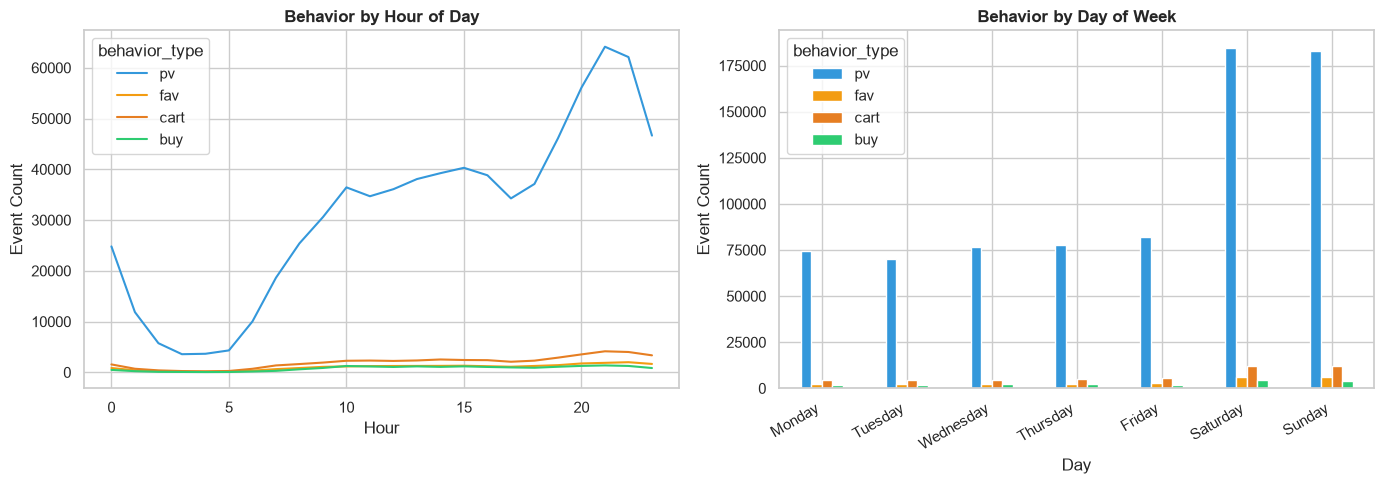

In [14]:
print("TIME PATTERNS")

df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.day_name()

# Hour of day
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

hour_behavior = df.groupby(['hour', 'behavior_type']).size().unstack(fill_value=0)
hour_behavior[['pv','fav','cart','buy']].plot(ax=axes[0],
    color=['#3498db','#f39c12','#e67e22','#2ecc71'])
axes[0].set_title('Behavior by Hour of Day', fontweight='bold')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Event Count')

# Day of week
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_behavior = df.groupby(['dayofweek', 'behavior_type']).size().unstack(fill_value=0)
day_behavior = day_behavior.reindex(day_order)
day_behavior[['pv','fav','cart','buy']].plot(kind='bar', ax=axes[1],
    color=['#3498db','#f39c12','#e67e22','#2ecc71'])
axes[1].set_title('Behavior by Day of Week', fontweight='bold')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Event Count')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [15]:
pairs = df.groupby(['user_id', 'item_id', 'category_id'])['behavior_type'].apply(list).reset_index()
pairs.columns = ['user_id', 'item_id', 'category_id', 'behaviors']

# Target variable
pairs['purchased'] = pairs['behaviors'].apply(lambda x: int('buy' in x))

print(f"Total user-item pairs: {len(pairs):,}")
print(f"Purchased pairs: {pairs['purchased'].sum():,} ({pairs['purchased'].mean()*100:.2f}%)")

Total user-item pairs: 644,064
Purchased pairs: 17,841 (2.77%)


In [16]:
pairs['view_count'] = pairs['behaviors'].apply(lambda x: x.count('pv'))
pairs['fav_count']  = pairs['behaviors'].apply(lambda x: x.count('fav'))
pairs['cart_count'] = pairs['behaviors'].apply(lambda x: x.count('cart'))

# Binary flags
pairs['has_view'] = (pairs['view_count'] > 0).astype(int)
pairs['has_fav']  = (pairs['fav_count']  > 0).astype(int)
pairs['has_cart'] = (pairs['cart_count'] > 0).astype(int)

# Depth score — weighted sum (pv=1, fav=2, cart=3)
pairs['depth_score'] = (
    pairs['view_count'] * 1 +
    pairs['fav_count']  * 2 +
    pairs['cart_count'] * 3
)

In [17]:
df['date'] = df['datetime'].dt.date

session_count = (df.groupby(['user_id', 'item_id'])['date']
                   .nunique()
                   .reset_index()
                   .rename(columns={'date': 'session_count'}))

pairs = pairs.merge(session_count, on=['user_id', 'item_id'], how='left')
pairs['session_count'] = pairs['session_count'].fillna(1)

In [18]:
# Category-level control: average depth score per category.
# NOTE: this full-data version is only saved for reference. The modeling section
# recomputes it from TRAINING pairs only, so test pairs never influence a feature.
category_avg_depth = (pairs.groupby('category_id')['depth_score']
                           .mean()
                           .reset_index()
                           .rename(columns={'depth_score': 'category_avg_depth'}))

pairs = pairs.merge(category_avg_depth, on='category_id', how='left')

In [19]:
# Recency & engagement span features
# For each user-item pair, find the first and last time the user interacted with it
pair_times = (df.groupby(['user_id', 'item_id'])['datetime']
                .agg(first_seen='min', last_seen='max')
                .reset_index())

max_date = df['datetime'].max()  # last timestamp in the (cleaned) dataset

# days_since_last: how long ago (relative to the end of the dataset) the user last touched the item
pair_times['days_since_last'] = (max_date - pair_times['last_seen']).dt.total_seconds() / 86400

# engagement_span_days: days between first and last interaction (0 if all on the same day)
pair_times['engagement_span_days'] = (pair_times['last_seen'].dt.normalize()
                                      - pair_times['first_seen'].dt.normalize()).dt.days

pairs = pairs.merge(pair_times[['user_id', 'item_id', 'days_since_last', 'engagement_span_days']],
                    on=['user_id', 'item_id'], how='left')

print(pairs[['days_since_last', 'engagement_span_days']].describe())

       days_since_last  engagement_span_days
count      644064.0000           644064.0000
mean            3.9628                0.2317
std             2.6877                0.9555
min             0.0000                0.0000
25%             1.4265                0.0000
50%             3.6330                0.0000
75%             6.3238                0.0000
max             9.0000                8.0000


In [20]:
# funnel_steps: number of distinct pre-purchase behaviors the user reached on this item
# e.g. pv only = 1, pv+cart = 2, pv+fav+cart = 3
# NOTE: 'buy' is excluded on purpose — counting it would leak the target into the feature
pre_purchase = {'pv', 'fav', 'cart'}
pairs['funnel_steps'] = pairs['behaviors'].apply(lambda x: len(set(x) & pre_purchase))

print(pairs['funnel_steps'].value_counts().sort_index())

# Quick sanity check: purchase rate should rise with funnel depth
print("\nPurchase rate by funnel_steps:")
print(pairs.groupby('funnel_steps')['purchased'].mean())

funnel_steps
0      4992
1    607411
2     30993
3       668
Name: count, dtype: int64

Purchase rate by funnel_steps:
funnel_steps
0   1.0000
1   0.0159
2   0.0988
3   0.1766
Name: purchased, dtype: float64


In [21]:
feature_cols = [
    'user_id', 'item_id','category_id',
    'has_view',                          # v1 baseline feature
    'view_count', 'has_fav', 'has_cart', # v2 depth features
    'fav_count',                         # v2 depth features
    'depth_score', 'session_count',      # v2 depth features
    'days_since_last',                   # v2 recency feature
    'engagement_span_days',              # v2 engagement span feature
    'funnel_steps',                      # v2 funnel depth feature
    'category_avg_depth',                # control variable
    'purchased'                          # target
]

model_df = pairs[feature_cols].copy()
model_df = model_df.dropna()

print(f"Final dataset: {len(model_df):,} rows")
print(f"Purchase rate: {model_df['purchased'].mean()*100:.2f}%")
print(model_df.describe())

import os
save_path = '/Users/madhumithachandrasekaran/data/model_ready.csv'
os.makedirs(os.path.dirname(save_path), exist_ok=True)
model_df.to_csv(save_path, index=False)

Final dataset: 644,064 rows
Purchase rate: 2.77%
           user_id      item_id  category_id    has_view  view_count  \
count  644064.0000  644064.0000  644064.0000 644064.0000 644064.0000   
mean   508605.2180 2576940.5281 2685004.5943      0.9321      1.1624   
std    295208.9995 1485683.1325 1461078.3693      0.2516      0.8666   
min        66.0000      25.0000    2171.0000      0.0000      0.0000   
25%    252193.0000 1296798.0000 1320293.0000      1.0000      1.0000   
50%    503857.0000 2574297.0000 2640118.0000      1.0000      1.0000   
75%    762448.0000 3856669.7500 4145813.0000      1.0000      1.0000   
max   1017773.0000 5163006.0000 5161669.0000      1.0000     67.0000   

          has_fav    has_cart   fav_count  depth_score  session_count  \
count 644064.0000 644064.0000 644064.0000  644064.0000    644064.0000   
mean       0.0378      0.0726      0.0380       1.4613         1.1032   
std        0.1906      0.2595      0.1928       1.2046         0.3901   
min       

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

model_df = pd.read_csv('/Users/madhumithachandrasekaran/data/model_ready.csv')
print(f"Loaded: {len(model_df):,} rows")
print(f"Purchase rate: {model_df['purchased'].mean()*100:.2f}%")

Loaded: 644,064 rows
Purchase rate: 2.77%


In [23]:
# Features for each model
v1_features = ['has_view', 'category_avg_depth']
v2_features = ['view_count', 'has_fav', 'fav_count', 'has_cart',
               'depth_score', 'session_count', 'category_avg_depth',
               'days_since_last', 'engagement_span_days', 'funnel_steps']

all_features = list(dict.fromkeys(v1_features + v2_features))

# Split the pairs FIRST (same split as before: 80/20, stratified, seed 42)
train_df, test_df = train_test_split(
    model_df, test_size=0.2, random_state=42, stratify=model_df['purchased']
)
train_df, test_df = train_df.copy(), test_df.copy()

# Rebuild category_avg_depth from training pairs only, so the test set can't leak into it.
# Categories that never appear in training get the overall training average.
cat_depth = train_df.groupby('category_id')['depth_score'].mean()
global_depth = train_df['depth_score'].mean()
train_df['category_avg_depth'] = train_df['category_id'].map(cat_depth)
test_df['category_avg_depth'] = test_df['category_id'].map(cat_depth).fillna(global_depth)

X_train, y_train = train_df[all_features], train_df['purchased']
X_test, y_test = test_df[all_features], test_df['purchased']

unseen = (~test_df['category_id'].isin(cat_depth.index)).sum()
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Train purchase rate: {y_train.mean()*100:.2f}%")
print(f"Test purchase rate:  {y_test.mean()*100:.2f}%")
print(f"Test pairs in categories unseen in training: {unseen:,}")

Train: 515,251 rows | Test: 128,813 rows
Train purchase rate: 2.77%
Test purchase rate:  2.77%
Test pairs in categories unseen in training: 236


In [24]:
v1 = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
v1.fit(X_train[v1_features], y_train)

v1_probs = v1.predict_proba(X_test[v1_features])[:, 1]

v1_auc    = roc_auc_score(y_test, v1_probs)
v1_prauc  = average_precision_score(y_test, v1_probs)

print(" V1 BASELINE (Logistic Regression - view signal only) ")
print(f"ROC-AUC:  {v1_auc:.4f}")
print(f"PR-AUC:   {v1_prauc:.4f}")

 V1 BASELINE (Logistic Regression - view signal only) 
ROC-AUC:  0.6781
PR-AUC:   0.0933


In [25]:
purchase_rate = y_train.mean()
scale = (1 - purchase_rate) / purchase_rate  # handles class imbalance

v2 = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale,
    random_state=42,
    eval_metric='aucpr',
    verbosity=0
)
v2.fit(X_train[v2_features], y_train)

v2_probs = v2.predict_proba(X_test[v2_features])[:, 1]

v2_auc   = roc_auc_score(y_test, v2_probs)
v2_prauc = average_precision_score(y_test, v2_probs)

print("V2 ATTENTION SCORE (XGBoost — full depth features)")
print(f"ROC-AUC:  {v2_auc:.4f}")
print(f"PR-AUC:   {v2_prauc:.4f}")

V2 ATTENTION SCORE (XGBoost — full depth features)
ROC-AUC:  0.9068
PR-AUC:   0.5976


In [26]:
print("V1 vs V2 COMPARISON")
print(f"{'Metric':<12} {'V1 Baseline':>14} {'V2 Attention':>14} {'Lift':>10}")
print(f"{'ROC-AUC':<12} {v1_auc:>14.4f} {v2_auc:>14.4f} {(v2_auc-v1_auc)/v1_auc*100:>+9.1f}%")
print(f"{'PR-AUC':<12} {v1_prauc:>14.4f} {v2_prauc:>14.4f} {(v2_prauc-v1_prauc)/v1_prauc*100:>+9.1f}%")

V1 vs V2 COMPARISON
Metric          V1 Baseline   V2 Attention       Lift
ROC-AUC              0.6781         0.9068     +33.7%
PR-AUC               0.0933         0.5976    +540.2%


In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
}

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=scale,
    random_state=42,
    eval_metric='aucpr',
    verbosity=0
)

grid_search = GridSearchCV(
    xgb_base,
    param_grid,
    scoring='average_precision',  
    cv=3,
    n_jobs=-1,                    
    verbose=1
)

# Tune on the expanded V2 feature set (includes the new recency/funnel features)
print(f"Tuning on {len(v2_features)} features: {v2_features}")
grid_search.fit(X_train[v2_features], y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best CV PR-AUC:  {grid_search.best_score_:.4f}")

Tuning on 10 features: ['view_count', 'has_fav', 'fav_count', 'has_cart', 'depth_score', 'session_count', 'category_avg_depth', 'days_since_last', 'engagement_span_days', 'funnel_steps']
Fitting 3 folds for each of 54 candidates, totalling 162 fits



Best parameters: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 300, 'subsample': 1.0}
Best CV PR-AUC:  0.6024


In [28]:
v2 = xgb.XGBClassifier(
    **grid_search.best_params_,
    scale_pos_weight=scale,
    random_state=42,
    eval_metric='aucpr',
    verbosity=0
)

v2.fit(X_train[v2_features], y_train)
v2_probs = v2.predict_proba(X_test[v2_features])[:, 1]

v2_auc   = roc_auc_score(y_test, v2_probs)
v2_prauc = average_precision_score(y_test, v2_probs)

print("V2 TUNED RESULTS")
print(f"ROC-AUC:  {v2_auc:.4f}")
print(f"PR-AUC:   {v2_prauc:.4f}")

V2 TUNED RESULTS
ROC-AUC:  0.9122
PR-AUC:   0.6127


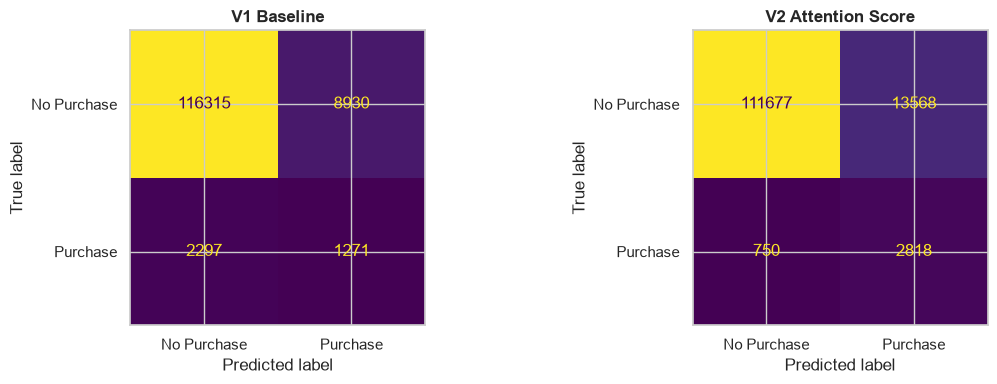

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use 0.5 threshold
v1_preds = (v1_probs >= 0.5).astype(int)
v2_preds = (v2_probs >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, preds, title in zip(axes,
                             [v1_preds, v2_preds],
                             ['V1 Baseline', 'V2 Attention Score']):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['No Purchase', 'Purchase']).plot(
        ax=ax, colorbar=False)
    ax.set_title(title, fontweight='bold')

plt.tight_layout()
plt.show()

In [30]:
print("V1 BASELINE")
print(classification_report(y_test, v1_preds,
      target_names=['No Purchase', 'Purchase']))

print("V2 ATTENTION SCORE")
print(classification_report(y_test, v2_preds,
      target_names=['No Purchase', 'Purchase']))

V1 BASELINE
              precision    recall  f1-score   support

 No Purchase       0.98      0.93      0.95    125245
    Purchase       0.12      0.36      0.18      3568

    accuracy                           0.91    128813
   macro avg       0.55      0.64      0.57    128813
weighted avg       0.96      0.91      0.93    128813

V2 ATTENTION SCORE
              precision    recall  f1-score   support

 No Purchase       0.99      0.89      0.94    125245
    Purchase       0.17      0.79      0.28      3568

    accuracy                           0.89    128813
   macro avg       0.58      0.84      0.61    128813
weighted avg       0.97      0.89      0.92    128813



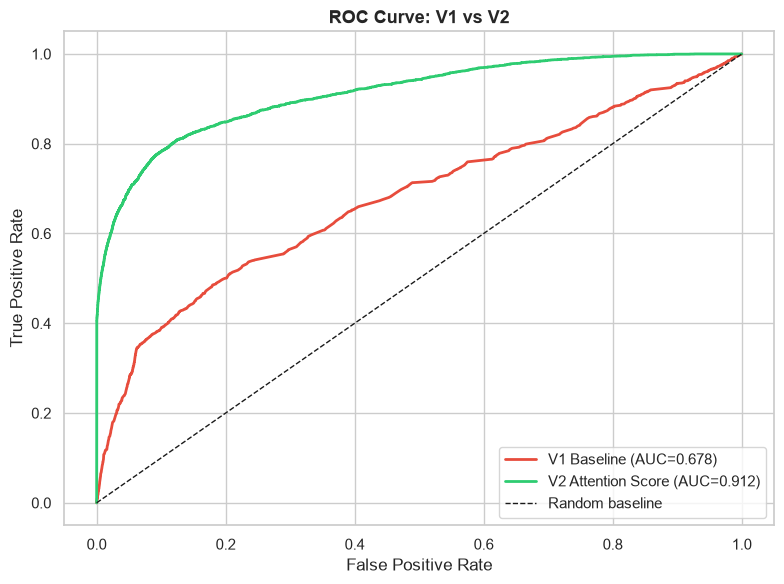

In [31]:
from sklearn.metrics import roc_curve

v1_fpr, v1_tpr, _ = roc_curve(y_test, v1_probs)
v2_fpr, v2_tpr, _ = roc_curve(y_test, v2_probs)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(v1_fpr, v1_tpr, color='#e74c3c', linewidth=2,
        label=f'V1 Baseline (AUC={v1_auc:.3f})')
ax.plot(v2_fpr, v2_tpr, color='#2ecc71', linewidth=2,
        label=f'V2 Attention Score (AUC={v2_auc:.3f})')
ax.plot([0,1], [0,1], 'k--', linewidth=1, label='Random baseline')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve: V1 vs V2', fontweight='bold', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

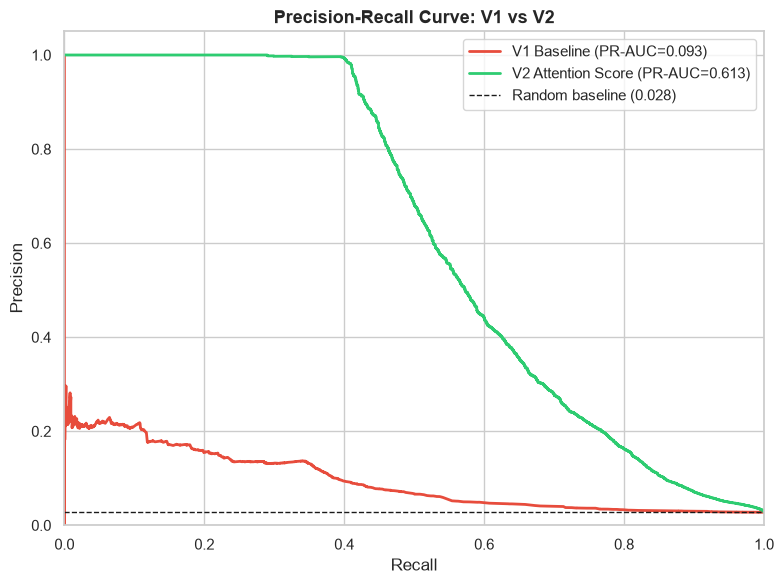

In [32]:
from sklearn.metrics import precision_recall_curve

# PR curve is more informative than ROC here because purchases are rare
v1_prec, v1_rec, _ = precision_recall_curve(y_test, v1_probs)
v2_prec, v2_rec, _ = precision_recall_curve(y_test, v2_probs)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(v1_rec, v1_prec, color='#e74c3c', linewidth=2,
        label=f'V1 Baseline (PR-AUC={v1_prauc:.3f})')
ax.plot(v2_rec, v2_prec, color='#2ecc71', linewidth=2,
        label=f'V2 Attention Score (PR-AUC={v2_prauc:.3f})')

# A random classifier's precision equals the positive rate
ax.axhline(y=y_test.mean(), color='k', linestyle='--', linewidth=1,
           label=f'Random baseline ({y_test.mean():.3f})')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curve: V1 vs V2', fontweight='bold', fontsize=13)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

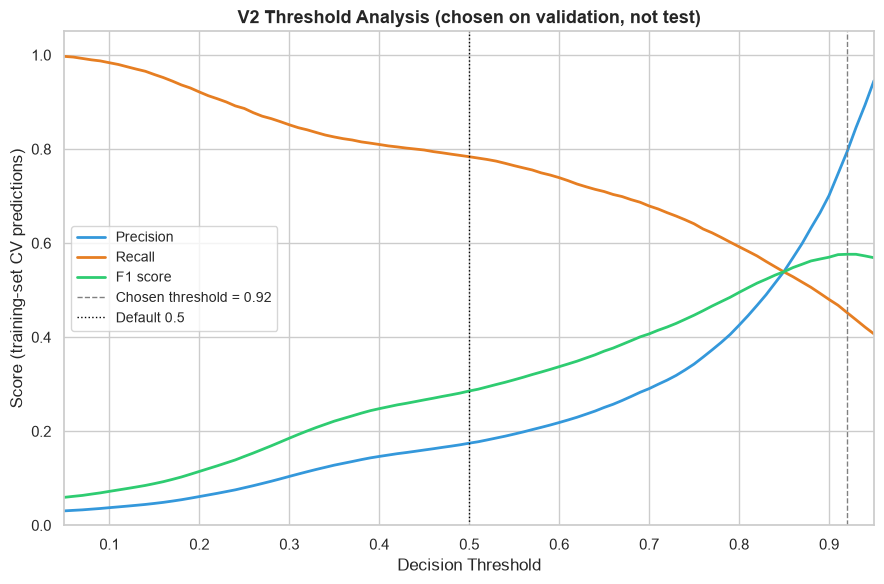

Threshold chosen on training-set CV predictions: 0.92
  Validation F1: 0.5762

TEST SET at threshold 0.92:
  Precision: 0.7903
  Recall:    0.4658
  F1:        0.5861
  TN=124,804  FP=441  FN=1,906  TP=1,662


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Choose the cutoff WITHOUT looking at the test set.
# Out-of-fold predictions on the training data act as a validation set:
# every training pair is scored by a model that never saw it.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
v2_cv_model = xgb.XGBClassifier(**grid_search.best_params_, scale_pos_weight=scale,
                                random_state=42, eval_metric='aucpr', verbosity=0)
oof_probs = cross_val_predict(v2_cv_model, X_train[v2_features], y_train,
                              cv=cv, method='predict_proba')[:, 1]

thresholds = np.arange(0.05, 0.951, 0.01)
precisions, recalls, f1s = [], [], []
for t in thresholds:
    preds = (oof_probs >= t).astype(int)
    precisions.append(precision_score(y_train, preds, zero_division=0))
    recalls.append(recall_score(y_train, preds, zero_division=0))
    f1s.append(f1_score(y_train, preds, zero_division=0))

# Threshold that maximises F1 on the validation (out-of-fold) predictions
best_idx = int(np.argmax(f1s))
best_t = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(thresholds, precisions, color='#3498db', linewidth=2, label='Precision')
ax.plot(thresholds, recalls,    color='#e67e22', linewidth=2, label='Recall')
ax.plot(thresholds, f1s,        color='#2ecc71', linewidth=2, label='F1 score')
ax.axvline(x=best_t, color='gray', linestyle='--', linewidth=1,
           label=f'Chosen threshold = {best_t:.2f}')
ax.axvline(x=0.5, color='black', linestyle=':', linewidth=1, label='Default 0.5')

ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score (training-set CV predictions)', fontsize=12)
ax.set_title('V2 Threshold Analysis (chosen on validation, not test)', fontweight='bold', fontsize=13)
ax.set_xlim(0.05, 0.95)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"Threshold chosen on training-set CV predictions: {best_t:.2f}")
print(f"  Validation F1: {f1s[best_idx]:.4f}")

# Now apply that fixed cutoff to the untouched test set — reported once
test_preds = (v2_probs >= best_t).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
print(f"\nTEST SET at threshold {best_t:.2f}:")
print(f"  Precision: {precision_score(y_test, test_preds):.4f}")
print(f"  Recall:    {recall_score(y_test, test_preds):.4f}")
print(f"  F1:        {f1_score(y_test, test_preds):.4f}")
print(f"  TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

# Note: scale_pos_weight pushes V2's scores upward, so the useful cutoff
# sits well above 0.5 — the default threshold is not a good choice here.

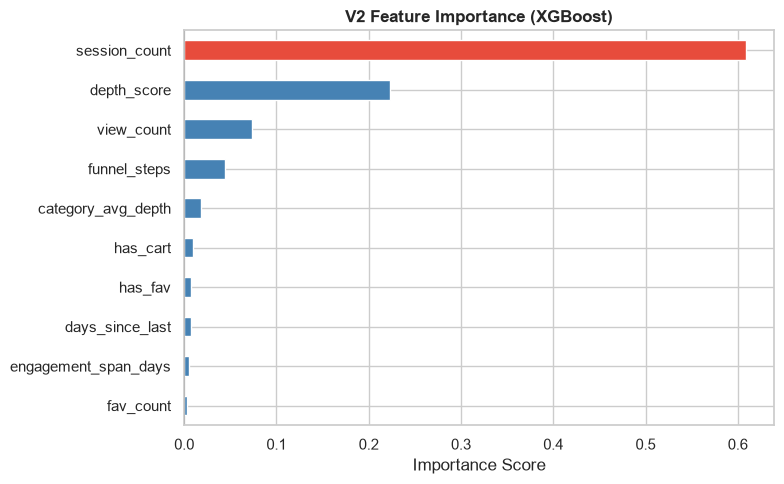


Feature importance ranked (tuned V2, expanded features):
session_count          0.6088
depth_score            0.2227
view_count             0.0732
funnel_steps           0.0445
category_avg_depth     0.0186
has_cart               0.0095
has_fav                0.0075
days_since_last        0.0073
engagement_span_days   0.0048
fav_count              0.0034


In [34]:
importance = pd.Series(
    v2.feature_importances_,
    index=v2_features
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c' if i == importance.index[-1] else 'steelblue'
          for i in importance.index]
importance.plot(kind='barh', ax=ax, color=colors, edgecolor='white')

ax.set_title('V2 Feature Importance (XGBoost)', fontweight='bold')
ax.set_xlabel('Importance Score')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

print("\nFeature importance ranked (tuned V2, expanded features):")
print(importance.sort_values(ascending=False).to_string())

In [35]:
# Overfitting check: training vs test scores for both final models
v1_train_probs = v1.predict_proba(X_train[v1_features])[:, 1]
v2_train_probs = v2.predict_proba(X_train[v2_features])[:, 1]

overfit = pd.DataFrame({
    'Train ROC-AUC': [roc_auc_score(y_train, v1_train_probs), roc_auc_score(y_train, v2_train_probs)],
    'Test ROC-AUC':  [v1_auc, v2_auc],
    'Train PR-AUC':  [average_precision_score(y_train, v1_train_probs),
                      average_precision_score(y_train, v2_train_probs)],
    'Test PR-AUC':   [v1_prauc, v2_prauc],
}, index=['V1 Logistic Regression', 'V2 XGBoost (tuned)'])
overfit['PR-AUC gap'] = overfit['Train PR-AUC'] - overfit['Test PR-AUC']
print(overfit.round(4).to_string())

# A small gap only says the model isn't memorising the training pairs.
# It can't rule out leakage: train and test share the same users and days.

                        Train ROC-AUC  Test ROC-AUC  Train PR-AUC  Test PR-AUC  PR-AUC gap
V1 Logistic Regression         0.6850        0.6781        0.0829       0.0933     -0.0105
V2 XGBoost (tuned)             0.9273        0.9122        0.6278       0.6127      0.0151


In [36]:
# Fair comparison: separate the effect of the MODEL from the effect of the FEATURES.
# V1 vs V2 changes both at once, so try every combination.
# Scored by 3-fold CV PR-AUC on the training set only — the test set stays untouched.
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def lr_model():
    # Scaling keeps logistic regression stable on the count features
    return make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))

def xgb_model():
    return xgb.XGBClassifier(**grid_search.best_params_, scale_pos_weight=scale,
                             random_state=42, eval_metric='aucpr', verbosity=0)

combos = []
for model_name, make in [('Logistic Regression', lr_model), ('XGBoost', xgb_model)]:
    for feat_name, feats in [('V1 features (2)', v1_features), ('V2 features (10)', v2_features)]:
        scores = cross_val_score(make(), X_train[feats], y_train, cv=cv, scoring='average_precision')
        combos.append({'Model': model_name, 'Features': feat_name,
                       'CV PR-AUC': scores.mean(), 'Std': scores.std()})

combos = pd.DataFrame(combos)
print(combos.round(4).to_string(index=False))
print("\nPivot (rows = model, columns = features):")
print(combos.pivot(index='Model', columns='Features', values='CV PR-AUC').round(4))

              Model         Features  CV PR-AUC    Std
Logistic Regression  V1 features (2)     0.0830 0.0016
Logistic Regression V2 features (10)     0.2201 0.0033
            XGBoost  V1 features (2)     0.1424 0.0007
            XGBoost V2 features (10)     0.6018 0.0051

Pivot (rows = model, columns = features):
Features             V1 features (2)  V2 features (10)
Model                                                 
Logistic Regression           0.0830            0.2201
XGBoost                       0.1424            0.6018


In [37]:
# Ablation: how much does V2 lose when a feature group is removed?
# (Feature importance shows what the model USED; ablation shows what it NEEDS.)
ablations = {
    'All 10 features':                v2_features,
    'Without session_count':          [f for f in v2_features if f != 'session_count'],
    'Without depth_score':            [f for f in v2_features if f != 'depth_score'],
    'Without session_count & depth_score': [f for f in v2_features if f not in ('session_count', 'depth_score')],
    'Without the 4 new features':     [f for f in v2_features if f not in
                                       ('fav_count', 'days_since_last', 'engagement_span_days', 'funnel_steps')],
}

rows = []
for name, feats in ablations.items():
    scores = cross_val_score(xgb_model(), X_train[feats], y_train, cv=cv, scoring='average_precision')
    rows.append({'Feature set': name, 'n features': len(feats),
                 'CV PR-AUC': scores.mean(), 'Std': scores.std()})

ablation_df = pd.DataFrame(rows)
ablation_df['Change vs all'] = ablation_df['CV PR-AUC'] - ablation_df.loc[0, 'CV PR-AUC']
print(ablation_df.round(4).to_string(index=False))

                        Feature set  n features  CV PR-AUC    Std  Change vs all
                    All 10 features          10     0.6018 0.0051         0.0000
              Without session_count           9     0.5809 0.0044        -0.0210
                Without depth_score           9     0.5989 0.0046        -0.0030
Without session_count & depth_score           8     0.5785 0.0047        -0.0233
         Without the 4 new features           6     0.5999 0.0039        -0.0020


In [38]:
# "User A vs User B": same 5 views, spread over different numbers of days
five_views = model_df[model_df['view_count'] == 5]
user_a = five_views[five_views['session_count'] == 1]   # all 5 views on one day
user_b = five_views[five_views['session_count'] >= 3]   # 5 views across 3+ days

print(f"5 views on 1 day:     {user_a['purchased'].mean():.1%} bought  ({len(user_a):,} pairs)")
print(f"5 views on 3+ days:   {user_b['purchased'].mean():.1%} bought  ({len(user_b):,} pairs)")
print(f"Ratio: {user_b['purchased'].mean() / user_a['purchased'].mean():.1f}x")

5 views on 1 day:     13.0% bought  (818 pairs)
5 views on 3+ days:   25.3% bought  (1,080 pairs)
Ratio: 2.0x
